# Cool Sub-Neptunes (Bachelor project)

## Import libraries

In [1]:
import sys
print(sys.executable)

/Users/felix/Documents/GitHub/atmodeller/atmodeller_env/bin/python3.12


In [2]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models

from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm

from scipy.interpolate import interp1d
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module=r"labellines.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"matplotlib.*")

# Uncomment below to install labellines if not already installed
#!pip install matplotlib-label-lines

from labellines import labelLine, labelLines

Atmodeller initialized with double precision (float64)


In [3]:
%pip install matplotlib-label-lines

/opt/homebrew/Cellar/python@3.12/3.12.11_1/Frameworks/Python.framework/Versions/3.12/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


# Model Setup

## Planet Parameters

In [4]:
# Mass 
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018Calculate using the M-R relation from Hakim et al. (2018) Icarus

# Surface temperature
surface_temperature = 3000  # Kelvin, temperature at the magma-atmosphere interface

# Atmosphere temperature
atmosphere_temperature = 300  # Kelvin, temperature at the top of the atmosphere, can be varied between 200-500K

# Extent of Magma Ocean: Full (mantle_melt_fraction = 1) or Partial (mantle_melt_fraction < 1)
mantle_melt_fraction = 1 # ensures strong gas-melt exchange

# Oxygen fugacity at the surface (magma-atmosphere interface)
number_of_realisations = 100
fO2_log10_shift = np.linspace(-3, 3, number_of_realisations) # can vary between -6 and 0: np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW0

## Elemental Budgets

In [5]:
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }

h_kg_single = (1 / 100) * planet_mass  # kg for 1 wt% H
h_kg  = np.full(number_of_realisations, h_kg_single)

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

## Chemical Species Setup

In [6]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )

O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)

# Condensates
#C_cr = Species.create_condensed("C", state="cr")      # solid carbon (graphite/diamond) -> state: crystalline
#H2O_l = Species.create_condensed("H2O", state="l")    # liquid water
#H2O_cr = Species.create_condensed("H2O", state="cr")  # ice

species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

In [7]:
cool_sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [8]:
solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

#IDEAL
model_ideal = InteriorAtmosphere(species_ideal)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shift)}

model_ideal.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_ideal = model_ideal.output

out_ideal.to_excel("HALLOIDEAL")

out_ideal.to_pickle("HALLOIDEAL")

[12:29:49 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[12:29:49 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[12:29:49 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[12:29:49 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[12:29:52 - atmodeller.c

In [9]:
FILE = "HALLOIDEAL.xlsx"

# Sheets corresponding to gas species
CANDIDATE_SHEETS = ["H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g", "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"]
# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

# ----------------------------
# X-AXIS: log10(fO2 shift)
# We read it from ANY gas sheet (e.g. H2)
# All sheets have identical ordering and values
# ----------------------------
o2_df = pd.read_excel(FILE, sheet_name="O2_g")
log10_fO2_shift = ref_df["log10dIW_1_bar"].to_numpy()       # from -6 to 0
order = np.argsort(log10_fO2_shift)
log10_fO2_shift = log10_fO2_shift[order]

# ----------------------------
# READ PARTIAL PRESSURE FOR EACH SPECIES
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()                  # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(log10_fO2_shift, p_bar, label=sheet)

ax_bar.set_xlabel("log$_{10}$(fO$_2$) [IW]")   # X-axis label
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4     # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("Partial pressures per gas vs log$_{10}$(fO$_2$/IW)")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

NameError: name 'ref_df' is not defined

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


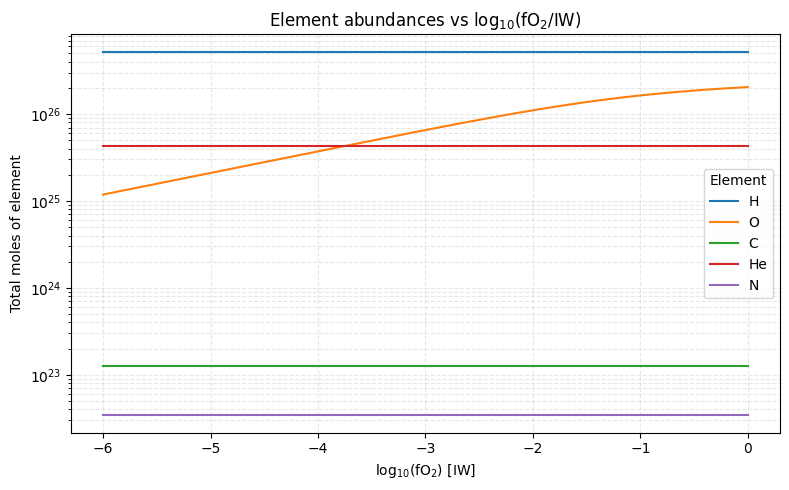

In [126]:
FILE = "HALLOIDEAL.xlsx"  # change if needed

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: log10(fO2/IW) from O2_g sheet
# ----------------------------
o2_df = pd.read_excel(FILE, sheet_name="O2_g")
log10_fO2_shift = o2_df["log10dIW_1_bar"].to_numpy()   # e.g. -6 → 0
order = np.argsort(log10_fO2_shift)
log10_fO2_shift = log10_fO2_shift[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(log10_fO2_shift, moles, label=label)

ax.set_xlabel(r"log$_{10}$(fO$_2$) [IW]")
ax.set_ylabel("Total moles of element")

# Often element abundances span many orders of magnitude:
ax.set_yscale("log")

plt.title("Element abundances vs log$_{10}$(fO$_2$/IW)")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()

In [120]:
#IDEAL vary mass of sub-Neptune
mass_factors = np.linspace(1.0, 10.0, number_of_realisations)
planet_masses = mass_factors * Earth_mass

surface_radii = 1.02 * (planet_masses / Earth_mass) ** 0.252 * Earth_radius

fO2_log10_shift_fixed = np.full(number_of_realisations, -3.0)

h_kg = (1 / 100) * planet_masses  # kg for 1 wt% H


# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_masses,   # array (N,)
    surface_radius=surface_radii, # array (N,)
    mantle_melt_fraction=mantle_melt_fraction,
)

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

model_ideal = InteriorAtmosphere(species_ideal)

# Fixed fO2 for all planets via IW buffer
fugacity_constraints = {
    O2_g.name: IronWustiteBuffer(fO2_log10_shift_fixed)  # array (N,)
}

# Single batched solve over all masses
model_ideal.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

out_ideal = model_ideal.output

out_ideal.to_excel("HALLOREAL")
out_ideal.to_pickle("HALLOREAL.pkl")

[13:30:20 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[13:30:20 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:30:20 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:30:21 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[13:30:22 - atmodeller.c

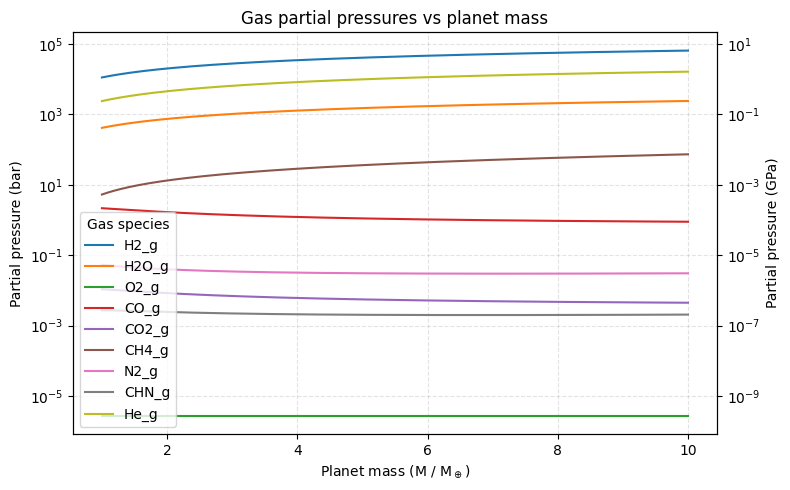

In [121]:
#Partial pressure per gas for varying mass
FILE = "cool_sub_neptune_ideal_withsol_varyM.xlsx"

# Sheets corresponding to gas species
CANDIDATE_SHEETS = ["H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g", "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"]


# ----------------------------
# LOAD WORKBOOK
# ----------------------------
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

# ----------------------------
# X-AXIS: planet mass (in Earth masses)
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
planet_mass = planet_df["planet_mass"].to_numpy()          # in kg
M_over_Mearth = planet_mass / Earth_mass                   # dimensionless

# sort by increasing planet mass
order = np.argsort(M_over_Mearth)
M_over_Mearth = M_over_Mearth[order]

# ----------------------------
# READ PARTIAL PRESSURE FOR EACH SPECIES
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()          # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(M_over_Mearth, p_bar, label=sheet)

ax_bar.set_xlabel(r"Planet mass (M / M$_\oplus$)")
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4     # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("Gas partial pressures vs planet mass")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


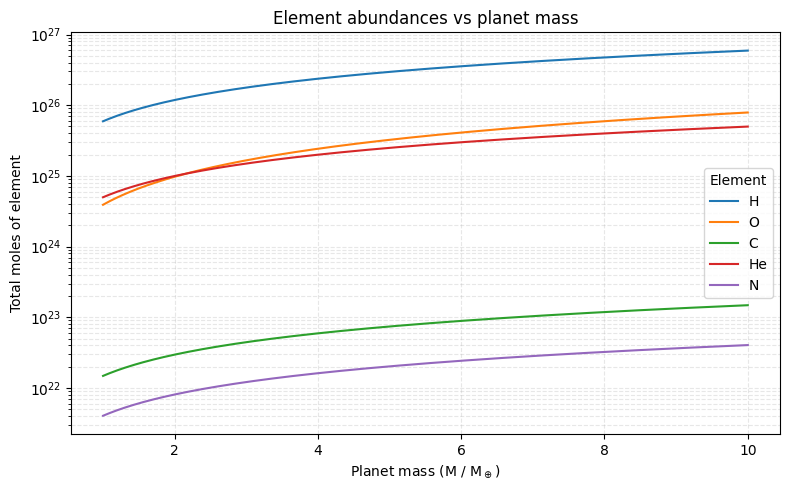

In [122]:
#Abundance per element for vaying mass
FILE = "cool_sub_neptune_ideal_withsol_varyM.xlsx"  # use your vary-M file

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# Earth mass in kg
EARTH_MASS = 5.972e24

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: planet mass (M / M_earth) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
planet_mass = planet_df["planet_mass"].to_numpy()         # in kg
M_over_Mearth = planet_mass / EARTH_MASS                  # dimensionless

# sort by increasing planet mass
order = np.argsort(M_over_Mearth)
M_over_Mearth = M_over_Mearth[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]          # apply same ordering as masses

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(M_over_Mearth, moles, label=label)

ax.set_xlabel(r"Planet mass (M / M$_\oplus$)")
ax.set_ylabel("Total moles of element")

# Often element abundances span many orders of magnitude:
ax.set_yscale("log")

plt.title("Element abundances vs planet mass")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()

In [101]:
#Vary envelope temperature
surface_temperatures = np.linspace(1800, 3500, number_of_realisations)
fO2_log10_shift_fixed = np.full(number_of_realisations, -3.0)

h_kg = (1 / 100) * planet_mass  # kg for 1 wt% H

# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * (O_masspercent_lodders09 / H_masspercent_lodders09)
c_kg_solar = h_kg * (C_masspercent_lodders09 / H_masspercent_lodders09)
n_kg_solar = h_kg * (N_masspercent_lodders09 / H_masspercent_lodders09)
he_kg_solar = h_kg * (He_masspercent_lodders09 / H_masspercent_lodders09)


mass_constraints = {
    "H":  h_kg,
    "He": he_kg_solar,
    "C":  c_kg_solar,
    "N":  n_kg_solar,
    # "O":  o_kg,
}

# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperatures,
    planet_mass=planet_mass,   
    surface_radius=surface_radius, 
    mantle_melt_fraction=mantle_melt_fraction,
)

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

model_ideal = InteriorAtmosphere(species_ideal)

# Fixed fO2 for all planets via IW buffer
fugacity_constraints = {
    O2_g.name: IronWustiteBuffer(fO2_log10_shift_fixed)
}

# Single batched solve over all masses
model_ideal.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

out_ideal = model_ideal.output

out_ideal.to_excel("cool_sub_neptune_ideal_withsol_varyT")
out_ideal.to_pickle("cool_sub_neptune_ideal_withsol_varyT.pkl")

[17:32:04 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw')
[17:32:04 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:32:04 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:32:04 - atmodeller.classes             - INFO     ] - Attempting to solve 500 model(s)
[17:32:06 - atmodeller.c

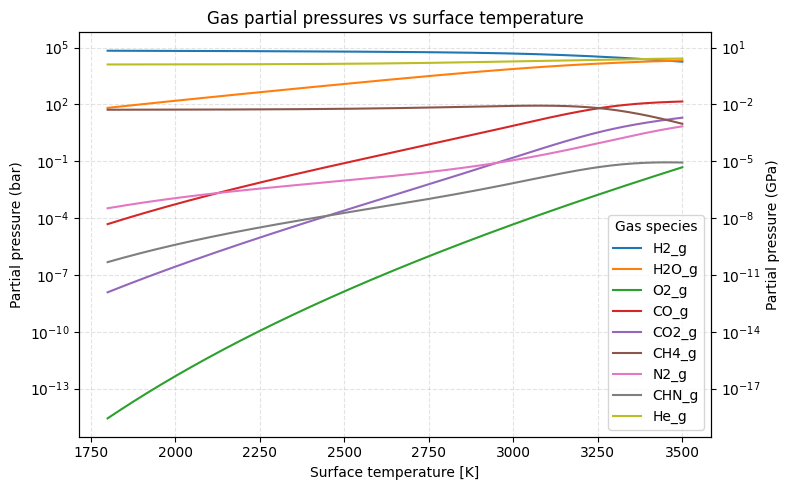

In [130]:
#partial pressure per gas for varying T
FILE = "cool_sub_neptune_ideal_withsol_varyT.xlsx"

# Sheets corresponding to gas species
CANDIDATE_SHEETS = ["H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g", "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"]

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

# ----------------------------
# X-AXIS: surface temperature (K) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
surface_T = planet_df["surface_temperature"].to_numpy()    # in K

# sort by increasing temperature
order = np.argsort(surface_T)
surface_T = surface_T[order]

# ----------------------------
# READ PARTIAL PRESSURE FOR EACH SPECIES
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()          # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(surface_T, p_bar, label=sheet)

ax_bar.set_xlabel("Surface temperature [K]")
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4     # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("Gas partial pressures vs surface temperature")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


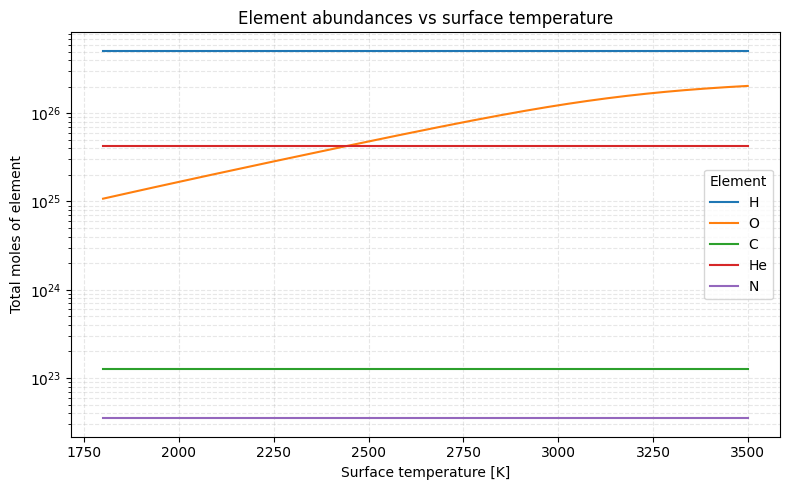

In [131]:
#abundance per element
FILE = "cool_sub_neptune_ideal_withsol_varyT.xlsx"  # vary-T file

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: surface temperature (K) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
surface_T = planet_df["surface_temperature"].to_numpy()    # in K

# sort by increasing surface temperature
order = np.argsort(surface_T)
surface_T = surface_T[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]          # apply same ordering as temperatures

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(surface_T, moles, label=label)

ax.set_xlabel("Surface temperature [K]")
ax.set_ylabel("Total moles of element")

# Element abundances often span many orders of magnitude:
ax.set_yscale("log")

plt.title("Element abundances vs surface temperature")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()

In [106]:
#REAL vary fO2
fO2_log10_shift = np.linspace(-6, 0, number_of_realisations) # can vary between -6 and 0: np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW0

h_kg_single = (1 / 100) * planet_mass  # kg for 1 wt% H

h_kg  = np.full(number_of_realisations, h_kg_single)


# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * (O_masspercent_lodders09 / H_masspercent_lodders09)
c_kg_solar = h_kg * (C_masspercent_lodders09 / H_masspercent_lodders09)
n_kg_solar = h_kg * (N_masspercent_lodders09 / H_masspercent_lodders09)
he_kg_solar = h_kg * (He_masspercent_lodders09 / H_masspercent_lodders09)


mass_constraints = {
    "H":  h_kg,
    "He": he_kg_solar,
    "C":  c_kg_solar,
    "N":  n_kg_solar,
    # "O":  o_kg,
}

cool_sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,   
    surface_radius=surface_radius, 
    mantle_melt_fraction=mantle_melt_fraction,
)

fugacity_constraints = {
    O2_g.name: IronWustiteBuffer(fO2_log10_shift)
}

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

model_real = InteriorAtmosphere(species_real)

model_real.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_real = model_real.output

out_real.to_excel("cool_sub_neptune_real_withsol_varyfO2")

out_real.to_pickle("cool_sub_neptune_real_withsol_varyfO2.pkl")

[17:43:00 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:43:00 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:43:00 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[17:43:00 - atmodeller.classes             - IN

Gas sheets found: ['H2_g', 'H2O_g', 'O2_g', 'CO_g', 'CO2_g', 'CH4_g', 'N2_g', 'CHN_g', 'He_g']


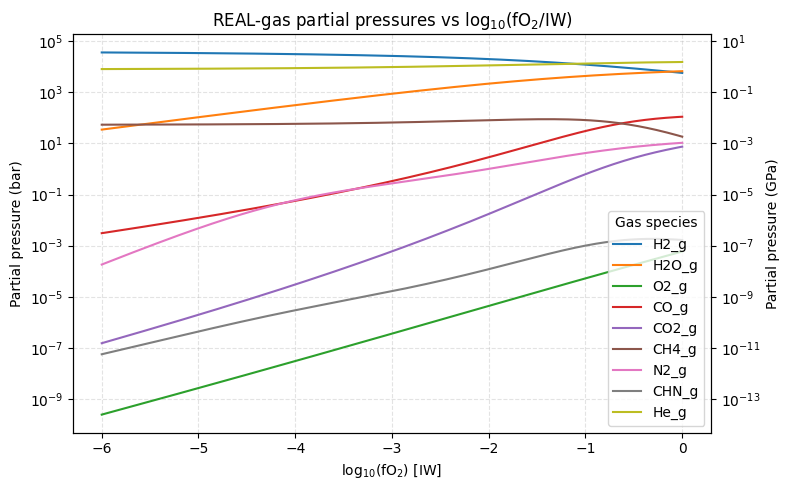

In [132]:
#Plot partial pressure vs log10(fO2) REAL
FILE = "cool_sub_neptune_real_withsol_varyfO2.xlsx"  # real-gas output

# Sheets corresponding to gas species (same names as ideal case)
CANDIDATE_SHEETS = ["H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
                    "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"]

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

print("Gas sheets found:", available_gas_sheets)

# ----------------------------
# X-AXIS: log10(fO2/IW) from O2_g sheet
# ----------------------------
o2_df = pd.read_excel(FILE, sheet_name="O2_g")
# column that goes from -6 to 0 (your IW–6 → IW0 shift)
log10_fO2_shift = o2_df["log10dIW_1_bar"].to_numpy()
order = np.argsort(log10_fO2_shift)
log10_fO2_shift = log10_fO2_shift[order]

# ----------------------------
# READ PARTIAL PRESSURE FOR EACH SPECIES
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()  # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(log10_fO2_shift, p_bar, label=sheet)

ax_bar.set_xlabel(r"log$_{10}$(fO$_2$) [IW]")
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4  # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("REAL-gas partial pressures vs log$_{10}$(fO$_2$/IW)")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


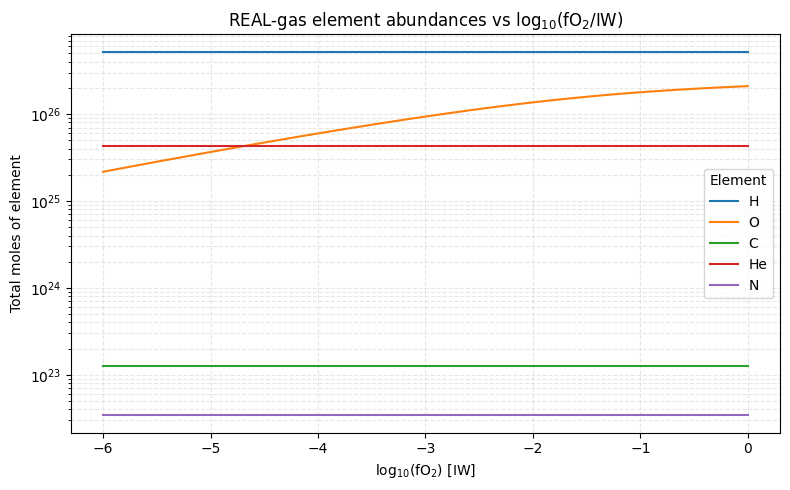

In [133]:
FILE = "cool_sub_neptune_real_withsol_varyfO2.xlsx"  # REAL-gas output

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: log10(fO2/IW) from O2_g sheet
# ----------------------------
o2_df = pd.read_excel(FILE, sheet_name="O2_g")
log10_fO2_shift = o2_df["log10dIW_1_bar"].to_numpy()   # e.g. -6 → 0
order = np.argsort(log10_fO2_shift)
log10_fO2_shift = log10_fO2_shift[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(log10_fO2_shift, moles, label=label)

ax.set_xlabel(r"log$_{10}$(fO$_2$) [IW]")
ax.set_ylabel("Total moles of element")

# Often element abundances span many orders of magnitude:
ax.set_yscale("log")

plt.title("REAL-gas element abundances vs log$_{10}$(fO$_2$/IW)")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()

In [114]:
#REAL vary sub-Neptune mass
mass_factors = np.linspace(1.0, 10.0, number_of_realisations)
planet_masses = mass_factors * Earth_mass

surface_radii = 1.02 * (planet_masses / Earth_mass) ** 0.252 * Earth_radius

fO2_log10_shift_fixed = np.full(number_of_realisations, -3.0)

h_kg = (1 / 100) * planet_masses  # kg for 1 wt% H

# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * (O_masspercent_lodders09 / H_masspercent_lodders09)
c_kg_solar = h_kg * (C_masspercent_lodders09 / H_masspercent_lodders09)
n_kg_solar = h_kg * (N_masspercent_lodders09 / H_masspercent_lodders09)
he_kg_solar = h_kg * (He_masspercent_lodders09 / H_masspercent_lodders09)


mass_constraints = {
    "H":  h_kg,   # array length N
    "He": he_kg_solar,
    "C":  c_kg_solar,
    "N":  n_kg_solar,
    # "O":  o_kg,
}

# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_masses,   # array (N,)
    surface_radius=surface_radii, # array (N,)
    mantle_melt_fraction=mantle_melt_fraction,
)


fugacity_constraints = {
    O2_g.name: IronWustiteBuffer(fO2_log10_shift_fixed)
}

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)

model_real = InteriorAtmosphere(species_real)

model_real.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_real = model_real.output

out_real.to_excel("cool_sub_neptune_real_withsol_varyM")

out_real.to_pickle("cool_sub_neptune_real_withsol_varyM.pkl")

[18:07:31 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[18:07:31 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:07:31 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[18:07:31 - atmodeller.classes             - IN

Gas sheets found: ['H2_g', 'H2O_g', 'O2_g', 'CO_g', 'CO2_g', 'CH4_g', 'N2_g', 'CHN_g', 'He_g']


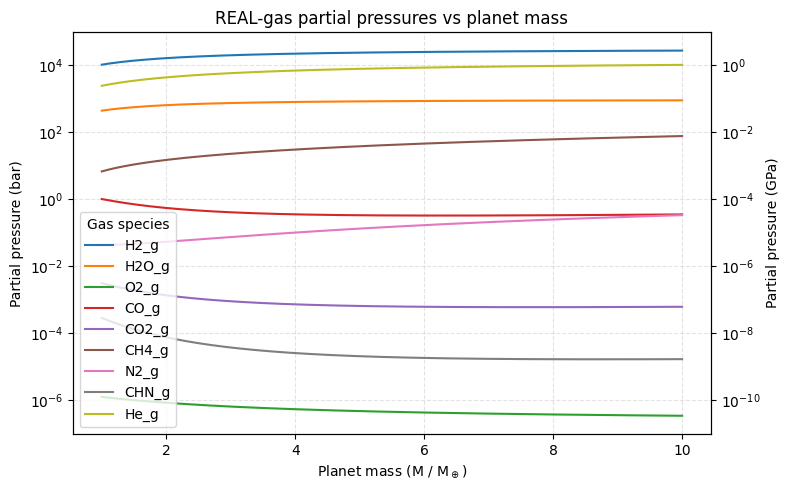

In [115]:
#Plot partial pressure vs varying sub-Neptune mass REAL
FILE = "cool_sub_neptune_real_withsol_varyM.xlsx"  # REAL-gas, varying mass
EARTH_MASS = 5.972e24  # kg

# Sheets corresponding to gas species
CANDIDATE_SHEETS = ["H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
                    "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"]

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)
available_gas_sheets = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]
print("Gas sheets found:", available_gas_sheets)

# ----------------------------
# X-AXIS: planet mass (in Earth masses)
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
planet_mass = planet_df["planet_mass"].to_numpy()          # in kg
M_over_Mearth = planet_mass / EARTH_MASS                   # dimensionless

# sort by increasing planet mass
order = np.argsort(M_over_Mearth)
M_over_Mearth = M_over_Mearth[order]

# ----------------------------
# READ PARTIAL PRESSURE FOR EACH SPECIES
# ----------------------------
species_pressures = {}

for sheet in available_gas_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)
    p_bar = df["pressure"].to_numpy()          # in bar
    species_pressures[sheet] = p_bar[order]

# ----------------------------
# PLOT (LEFT: bar, RIGHT: GPa)
# ----------------------------
fig, ax_bar = plt.subplots(figsize=(8, 5))

for sheet, p_bar in species_pressures.items():
    ax_bar.plot(M_over_Mearth, p_bar, label=sheet)

ax_bar.set_xlabel(r"Planet mass (M / M$_\oplus$)")
ax_bar.set_ylabel("Partial pressure (bar)")
ax_bar.set_yscale("log")

# ----------------------------
# RIGHT AXIS IN GPa
# ----------------------------
def bar_to_gpa(y_bar):
    return y_bar * 1e-4     # 1 bar = 1e-4 GPa

ax_gpa = ax_bar.twinx()
ymin_bar, ymax_bar = ax_bar.get_ylim()
ax_gpa.set_ylim(bar_to_gpa(ymin_bar), bar_to_gpa(ymax_bar))
ax_gpa.set_ylabel("Partial pressure (GPa)")
ax_gpa.set_yscale("log")

# ----------------------------
# AESTHETICS
# ----------------------------
plt.title("REAL-gas partial pressures vs planet mass")
ax_bar.grid(True, which="both", linestyle="--", alpha=0.35)
ax_bar.legend(title="Gas species", loc="best")

plt.tight_layout()
plt.show()

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


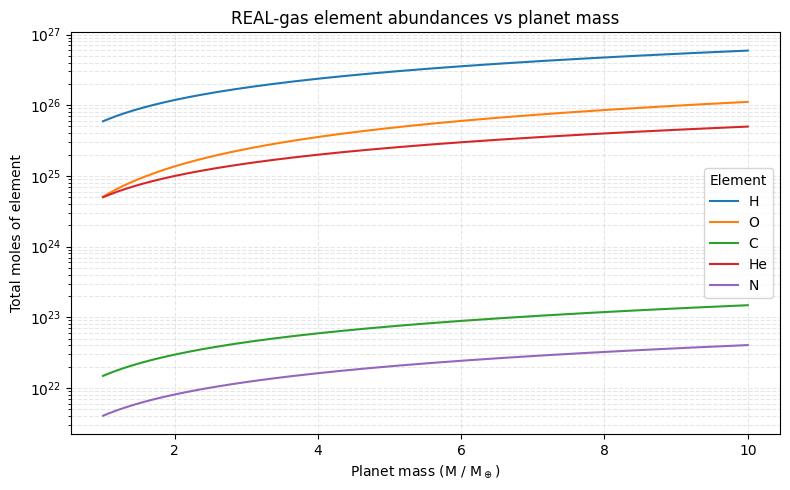

In [116]:
FILE = "cool_sub_neptune_real_withsol_varyM.xlsx"  # REAL-gas, vary-M run

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# Earth mass in kg
EARTH_MASS = 5.972e24

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: planet mass (M / M_earth) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
planet_mass = planet_df["planet_mass"].to_numpy()         # in kg
M_over_Mearth = planet_mass / EARTH_MASS                  # dimensionless

# sort by increasing planet mass
order = np.argsort(M_over_Mearth)
M_over_Mearth = M_over_Mearth[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]          # apply same ordering as masses

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(M_over_Mearth, moles, label=label)

ax.set_xlabel(r"Planet mass (M / M$_\oplus$)")
ax.set_ylabel("Total moles of element")

# Often element abundances span many orders of magnitude:
ax.set_yscale("log")

plt.title("REAL-gas element abundances vs planet mass")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()

In [117]:
#Vary envelope temperature REAL
# Mass 
Earth_mass = 5.972e24  # kg
planet_mass = 8.63 * Earth_mass # This can be varied between 1 and 10 Earth mass

# Radius
Earth_radius = 6371000  # meter
surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius # Calculate using the M-R relation from Hakim et al. (2018) Icarus

# Extent of Magma Ocean: Full (mantle_melt_fraction = 1) or Partial (mantle_melt_fraction < 1)
mantle_melt_fraction = 1 # ensures strong gas-melt exchange

surface_temperatures = np.linspace(1800, 3500, number_of_realisations)
fO2_log10_shift_fixed = np.full(number_of_realisations, -3.0)

h_kg = (1 / 100) * planet_mass  # kg for 1 wt% H

# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * (O_masspercent_lodders09 / H_masspercent_lodders09)
c_kg_solar = h_kg * (C_masspercent_lodders09 / H_masspercent_lodders09)
n_kg_solar = h_kg * (N_masspercent_lodders09 / H_masspercent_lodders09)
he_kg_solar = h_kg * (He_masspercent_lodders09 / H_masspercent_lodders09)


mass_constraints = {
    "H":  h_kg,
    "He": he_kg_solar,
    "C":  c_kg_solar,
    "N":  n_kg_solar,
    # "O":  o_kg,
}

# Planet with vectorized properties (one per realisation)
cool_sub_neptune = Planet(
    surface_temperature=surface_temperatures,
    planet_mass=planet_mass,   
    surface_radius=surface_radius, 
    mantle_melt_fraction=mantle_melt_fraction,
)

solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)


# Fixed fO2 for all planets via IW buffer
fugacity_constraints = {
    O2_g.name: IronWustiteBuffer(fO2_log10_shift_fixed)
}

model_real = InteriorAtmosphere(species_real)

model_real.solve(
    planet=cool_sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)
out_real = model_real.output

out_real.to_excel("cool_sub_neptune_real_withsol_varyT")

out_real.to_pickle("cool_sub_neptune_real_withsol_varyT.pkl")

[18:23:10 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[18:23:10 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:23:10 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[18:23:10 - atmodeller.classes             - IN

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import LogLocator, ScalarFormatter
from matplotlib.cm import get_cmap

# ===========================================================
# NATURE-STYLE
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.linewidth"] = 1.1
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.6
    plt.rcParams["grid.alpha"] = 0.3
    plt.rcParams["axes.prop_cycle"] = plt.cycler(
        color=get_cmap("tab10").colors
    )


# ===========================================================
# MAIN FIGURE
# ===========================================================
def plot_partial_pressure_temperature(file):

    set_nature_style()

    # Gas sheets
    CANDIDATE_SHEETS = [
        "H2_g", "H2O_g", "O2_g", "CO_g", "CO2_g",
        "CH4_g", "N2_g", "NH3_g", "CHN_g", "He_g"
    ]

    # Load workbook
    xls = pd.ExcelFile(file)
    available = [s for s in CANDIDATE_SHEETS if s in xls.sheet_names]

    # Temperature axis
    planet_df = pd.read_excel(file, sheet_name="planet")
    surface_T = planet_df["surface_temperature"].to_numpy()
    order = np.argsort(surface_T)
    surface_T = surface_T[order]

    # Partial pressures
    species_pressures = {}
    for sheet in available:
        df = pd.read_excel(file, sheet_name=sheet)
        p_bar = df["pressure"].to_numpy()
        species_pressures[sheet] = p_bar[order]

    # ======================================================
    # FIGURE
    # ======================================================
    fig, ax_bar = plt.subplots(figsize=(8, 6), dpi=300)

    # Plot lines
    for sheet, p_bar in species_pressures.items():
        ax_bar.plot(surface_T, p_bar, lw=2.3, label=sheet)

    # -------- Left Axis --------
    ax_bar.set_xlabel("Surface temperature (K)")
    ax_bar.set_ylabel("Partial pressure (bar)")
    ax_bar.set_yscale("log")

    # Log ticks fixed (prevents “d 0” tick labels)
    ax_bar.yaxis.set_major_locator(LogLocator(base=10))
    ax_bar.yaxis.set_major_formatter(ScalarFormatter())
    ax_bar.ticklabel_format(style='plain', axis='y')

    # -------- Right Axis --------
    ax_gpa = ax_bar.twinx()

    def bar_to_gpa(x): return x * 1e-4
    ymin, ymax = ax_bar.get_ylim()
    ax_gpa.set_ylim(bar_to_gpa(ymin), bar_to_gpa(ymax))

    ax_gpa.set_ylabel("Partial pressure (GPa)")
    ax_gpa.set_yscale("log")
    ax_gpa.yaxis.set_major_locator(LogLocator(base=10))
    ax_gpa.yaxis.set_major_formatter(ScalarFormatter())

    # -------- Clean spines --------
    ax_bar.spines["top"].set_visible(False)
    ax_bar.spines["right"].set_visible(False)
    ax_gpa.spines["top"].set_visible(False)

    # -------- Legend far right --------
    ax_bar.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.30, 1.00)   # <-- MOVED FURTHER RIGHT
    )

    # -------- Fix cropping / title clipping --------
    fig.suptitle("REAL-gas partial pressures vs surface temperature", fontsize=16)

    plt.subplots_adjust(
        top=0.92,
        right=0.78   # leaves extra room for legend
    )

    plt.show()


# ===========================================================
# RUN
# ===========================================================
plot_partial_pressure_temperature("cool_sub_neptune_real_withsol_varyT.xlsx")


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_49156/3561522425.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color=get_cmap("tab10").colors


FileNotFoundError: [Errno 2] No such file or directory: 'cool_sub_neptune_real_withsol_varyT.xlsx'

Detected element sheets: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']
Will plot elements: ['element_H', 'element_O', 'element_C', 'element_He', 'element_N']


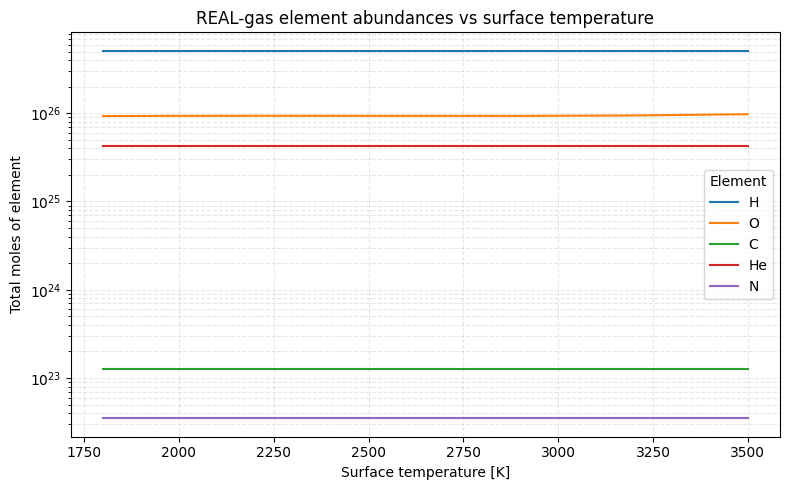

In [135]:
#abundance per element REAL
FILE = "cool_sub_neptune_real_withsol_varyT.xlsx"  # REAL-gas, vary-T file

# Element sheets and column with abundances
ELEMENT_SHEETS = ["element_H", "element_O", "element_C", "element_He", "element_N"]
MOLES_COL = "total_moles"

# ----------------------------
# LOAD WORKBOOK
# ----------------------------
xls = pd.ExcelFile(FILE)

# Keep only element sheets that actually exist in the file
available_element_sheets = [s for s in ELEMENT_SHEETS if s in xls.sheet_names]
print("Detected element sheets:", available_element_sheets)

# ----------------------------
# X-AXIS: surface temperature (K) from 'planet' sheet
# ----------------------------
planet_df = pd.read_excel(FILE, sheet_name="planet")
surface_T = planet_df["surface_temperature"].to_numpy()    # in K

# sort by increasing surface temperature
order = np.argsort(surface_T)
surface_T = surface_T[order]

# ----------------------------
# Y-AXIS: total moles for each element
# ----------------------------
element_moles = {}

for sheet in available_element_sheets:
    df = pd.read_excel(FILE, sheet_name=sheet)

    if MOLES_COL not in df.columns:
        print(f"Skipping {sheet}: column '{MOLES_COL}' not found.")
        continue

    moles = df[MOLES_COL].to_numpy()
    moles = moles[order]          # apply same ordering as temperatures

    element_moles[sheet] = moles

print("Will plot elements:", list(element_moles.keys()))

# ----------------------------
# PLOT
# ----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for sheet, moles in element_moles.items():
    # label elements nicely (strip "element_")
    label = sheet.replace("element_", "")
    ax.plot(surface_T, moles, label=label)

ax.set_xlabel("Surface temperature [K]")
ax.set_ylabel("Total moles of element")

# Element abundances often span many orders of magnitude:
ax.set_yscale("log")

plt.title("REAL-gas element abundances vs surface temperature")
ax.grid(True, which="both", linestyle="--", alpha=0.3)
ax.legend(title="Element", loc="best")

plt.tight_layout()
plt.show()